# Praktikum 3 - Regresi JST (MLP) pada Dataset PBL

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf

# Load dataset PBL
df = pd.read_csv('burnout_dataset1.csv')
df_sample = df.sample(n=2000, random_state=42)

num_cols = df_sample.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in ['Person_ID', 'Burnout_Score']]

X_raw = SimpleImputer(strategy='median').fit_transform(df_sample[feature_cols])
y_raw = df_sample[['Burnout_Score']].values

# Normalisasi
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X = scaler_X.fit_transform(X_raw)
y = scaler_y.fit_transform(y_raw)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model dasar regresi
tf.keras.utils.set_random_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(1),
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

# Evaluasi
preds_scaled = model.predict(X_test, verbose=0)
preds = scaler_y.inverse_transform(preds_scaled)
y_actual = scaler_y.inverse_transform(y_test)
mse_scaled = model.evaluate(X_test, y_test, verbose=0)
print(f"Test MSE (scaled): {mse_scaled:.4f}")
print("Contoh 5 Prediksi Burnout_Score vs Aktual:")
for p, a in zip(preds[:5].ravel(), y_actual[:5].ravel()):
    print(f"Prediksi: {p:.2f} | Aktual: {a:.2f}")

Test MSE (scaled): 0.1393
Contoh 5 Prediksi Burnout_Score vs Aktual:
Prediksi: 41.54 | Aktual: 47.00
Prediksi: 9.55 | Aktual: 9.00
Prediksi: 52.79 | Aktual: 49.00
Prediksi: 28.03 | Aktual: 10.00
Prediksi: -1.03 | Aktual: 3.00


# Tugas 4 - Eksperimen Variasi Learning Rate

In [2]:
learning_rates = [0.1, 0.05, 0.01, 0.001, 0.0001]
hasil_lr = []

for lr in learning_rates:
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    hist = m.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)
    loss_akhir = hist.history['loss'][-1]
    loss_uji = m.evaluate(X_test, y_test, verbose=0)
    hasil_lr.append({
        'Learning Rate': lr,
        'Final Train Loss (MSE)': round(loss_akhir, 5),
        'Test Loss (MSE)': round(loss_uji, 5),
    })

df_tugas4 = pd.DataFrame(hasil_lr)
df_tugas4

,Learning Rate,Final Train Loss (MSE),Test Loss (MSE)
0,0.1000,0.15037,0.20695
1,0.0500,0.13147,0.14789
2,0.0100,0.11085,0.16507
3,0.0010,0.11451,0.13927
4,0.0001,0.23057,0.25277


Berdasarkan pengujian variasi learning rate pada regresi Burnout_Score:

Nilai learning rate menentukan besarnya langkah pembaruan bobot pada setiap iterasi. Learning rate yang terlalu kecil (0.0001) membuat penurunan loss berjalan lambat sehingga belum optimal dalam 50 epoch. Nilai learning rate moderat (0.001 hingga 0.01) menghasilkan konvergensi stabil dan test MSE rendah, sedangkan learning rate yang terlalu besar (0.1) berisiko menyebabkan osilasi di sekitar titik minimum.

# MLP Regresi Burnout_Score (Arsitektur 64-32-1 dengan Kurva Validasi)

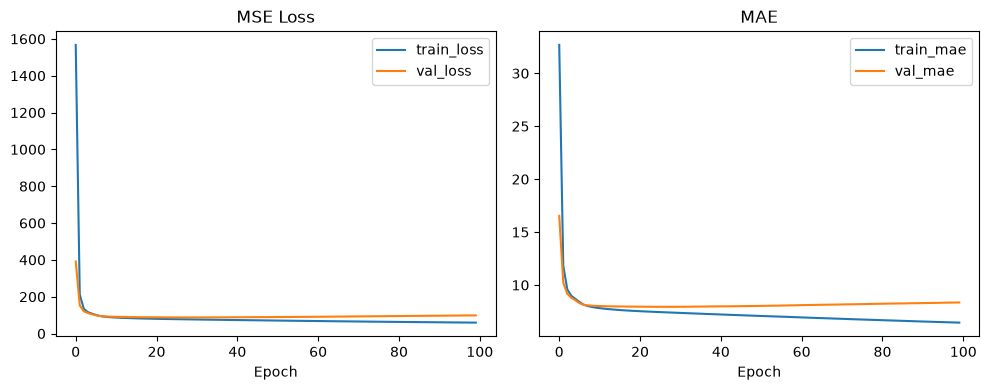

Validation RMSE: 9.9384
Validation MAE : 8.3508


In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

# 1. Load 5000 sampel dataset PBL
df_reg = df.sample(n=5000, random_state=42)
X_reg = SimpleImputer(strategy='median').fit_transform(df_reg[feature_cols])
y_reg = df_reg['Burnout_Score'].values

# 2. Preprocess
Xs = StandardScaler().fit_transform(X_reg)
X_tr, X_val, y_tr, y_val = train_test_split(Xs, y_reg, test_size=0.2, random_state=42)

# 3. Build model
tf.keras.utils.set_random_seed(42)
model_mlp = Sequential([
    Input(shape=(X_tr.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1),
])
model_mlp.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model_mlp.fit(
    X_tr, y_tr, validation_data=(X_val, y_val), epochs=100, batch_size=32, verbose=0
)

# 5. Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE Loss')
plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.xlabel('Epoch')
plt.tight_layout()
plt.show()

pred = model_mlp.predict(X_val, verbose=0).ravel()
rmse = np.sqrt(mean_squared_error(y_val, pred))
mae = mean_absolute_error(y_val, pred)
print(f"Validation RMSE: {rmse:.4f}")
print(f"Validation MAE : {mae:.4f}")